# DMV Practical: Time Series Analysis of Stock Prices

**Dataset:** `stock_prices.csv`

This dataset uses the columns `symbol`, `timestamp`, `open`, `high`, `low`, `close`, and `volume`. The code below matches those column names.

**In Google Colab:** upload `stock_prices.csv` to the session before running the notebook.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load dataset
df = pd.read_csv("stock_prices.csv")

print("First 5 rows:")
display(df.head())

print("\\nDataset shape:", df.shape)
print("\\nColumns:", df.columns.tolist())

First 5 rows:


,_id,symbol,timestamp,open,high,low,close,volume,is_live,interval
0,67684be1d5e7efabd1532871,AAPL,2023-01-03 14:30:00,130.279999,130.899994,125.230003,125.459999,27775505,False,1h
1,67684be1d5e7efabd1532872,AAPL,2023-01-03 15:30:00,125.459999,125.870003,124.730003,125.345001,18104999,False,1h
2,67684be1d5e7efabd1532873,AAPL,2023-01-03 16:30:00,125.350197,125.370003,124.349098,124.660004,11248777,False,1h
3,67684be1d5e7efabd1532874,AAPL,2023-01-03 17:30:00,124.660004,124.940002,124.190002,124.649902,8860080,False,1h
4,67684be1d5e7efabd1532875,AAPL,2023-01-03 18:30:00,124.669899,125.000000,124.190002,124.570000,8388062,False,1h


\nDataset shape: (3456, 10)
\nColumns: ['_id', 'symbol', 'timestamp', 'open', 'high', 'low', 'close', 'volume', 'is_live', 'interval']


## 1. Pre-process the data

In [2]:
# Convert timestamp to datetime
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

# Remove duplicate rows and rows with missing date/closing price
df = df.drop_duplicates()
df = df.dropna(subset=["timestamp", "close"])

# Sort data by stock symbol and time
df = df.sort_values(["symbol", "timestamp"])

# Make price and volume columns numeric
for col in ["open", "high", "low", "close", "volume"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["close"])
print("Cleaned data:")
display(df.head())
print("Rows after cleaning:", len(df))

Cleaned data:


,_id,symbol,timestamp,open,high,low,close,volume,is_live,interval
0,67684be1d5e7efabd1532871,AAPL,2023-01-03 14:30:00,130.279999,130.899994,125.230003,125.459999,27775505,False,1h
1,67684be1d5e7efabd1532872,AAPL,2023-01-03 15:30:00,125.459999,125.870003,124.730003,125.345001,18104999,False,1h
2,67684be1d5e7efabd1532873,AAPL,2023-01-03 16:30:00,125.350197,125.370003,124.349098,124.660004,11248777,False,1h
3,67684be1d5e7efabd1532874,AAPL,2023-01-03 17:30:00,124.660004,124.940002,124.190002,124.649902,8860080,False,1h
4,67684be1d5e7efabd1532875,AAPL,2023-01-03 18:30:00,124.669899,125.000000,124.190002,124.570000,8388062,False,1h


Rows after cleaning: 3456


## 2. Select one stock for analysis

In [3]:
# List available stock symbols
print("Available symbols:", sorted(df["symbol"].dropna().unique()))

# Use the first available symbol; change this value to another symbol if needed
stock = df["symbol"].dropna().iloc[0]
stock_df = df[df["symbol"] == stock].copy()
stock_df = stock_df.sort_values("timestamp")

print("Selected stock:", stock)
display(stock_df.head())

Available symbols: ['AAPL']
Selected stock: AAPL


,_id,symbol,timestamp,open,high,low,close,volume,is_live,interval
0,67684be1d5e7efabd1532871,AAPL,2023-01-03 14:30:00,130.279999,130.899994,125.230003,125.459999,27775505,False,1h
1,67684be1d5e7efabd1532872,AAPL,2023-01-03 15:30:00,125.459999,125.870003,124.730003,125.345001,18104999,False,1h
2,67684be1d5e7efabd1532873,AAPL,2023-01-03 16:30:00,125.350197,125.370003,124.349098,124.660004,11248777,False,1h
3,67684be1d5e7efabd1532874,AAPL,2023-01-03 17:30:00,124.660004,124.940002,124.190002,124.649902,8860080,False,1h
4,67684be1d5e7efabd1532875,AAPL,2023-01-03 18:30:00,124.669899,125.000000,124.190002,124.570000,8388062,False,1h


## 3. Visualize closing price over time

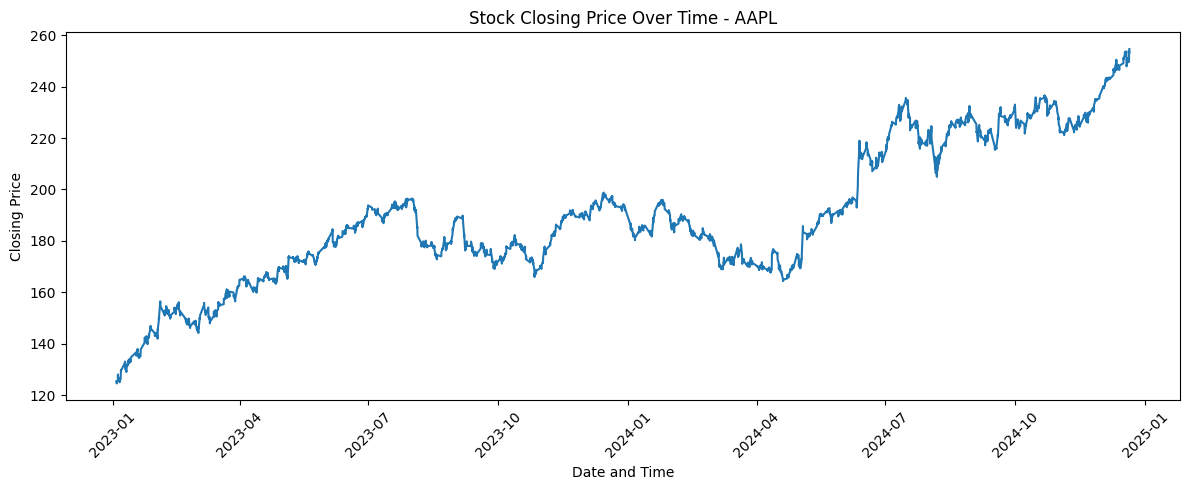

In [4]:
plt.figure(figsize=(12, 5))
plt.plot(stock_df["timestamp"], stock_df["close"])
plt.title("Stock Closing Price Over Time - " + str(stock))
plt.xlabel("Date and Time")
plt.ylabel("Closing Price")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4. Calculate daily/hourly returns and moving averages

In [5]:
# This dataset has hourly observations, so these are per-observation returns
stock_df["return_pct"] = stock_df["close"].pct_change() * 100
stock_df["MA_7"] = stock_df["close"].rolling(window=7).mean()
stock_df["MA_30"] = stock_df["close"].rolling(window=30).mean()

print("Average closing price:", round(stock_df["close"].mean(), 2))
print("Maximum closing price:", round(stock_df["close"].max(), 2))
print("Minimum closing price:", round(stock_df["close"].min(), 2))
print("Average volume:", round(stock_df["volume"].mean(), 2))
print("Average return per observation (%):", round(stock_df["return_pct"].mean(), 4))

display(stock_df[["timestamp", "close", "return_pct", "MA_7", "MA_30"]].head(10))

Average closing price: 189.04
Maximum closing price: 254.59
Minimum closing price: 124.57
Average volume: 6676111.34
Average return per observation (%): 0.022


,timestamp,close,return_pct,MA_7,MA_30
0,2023-01-03 14:30:00,125.459999,NaN,NaN,NaN
1,2023-01-03 15:30:00,125.345001,-0.091661,NaN,NaN
2,2023-01-03 16:30:00,124.660004,-0.546490,NaN,NaN
3,2023-01-03 17:30:00,124.649902,-0.008103,NaN,NaN
4,2023-01-03 18:30:00,124.570000,-0.064102,NaN,NaN
5,2023-01-03 19:30:00,124.620003,0.040141,NaN,NaN
6,2023-01-03 20:30:00,125.050003,0.345049,124.907845,NaN
7,2023-01-04 14:30:00,125.998299,0.758333,124.984744,NaN
8,2023-01-04 15:30:00,127.379997,1.096601,125.275458,NaN
9,2023-01-04 16:30:00,128.065002,0.537765,125.761887,NaN


## 5. Plot moving averages

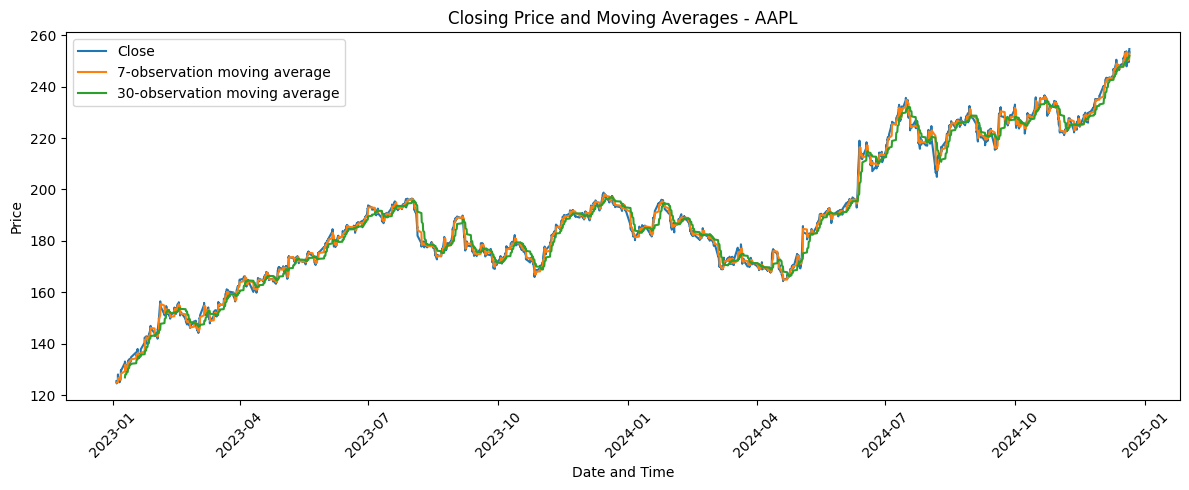

In [6]:
plt.figure(figsize=(12, 5))
plt.plot(stock_df["timestamp"], stock_df["close"], label="Close")
plt.plot(stock_df["timestamp"], stock_df["MA_7"], label="7-observation moving average")
plt.plot(stock_df["timestamp"], stock_df["MA_30"], label="30-observation moving average")
plt.title("Closing Price and Moving Averages - " + str(stock))
plt.xlabel("Date and Time")
plt.ylabel("Price")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Visualize returns

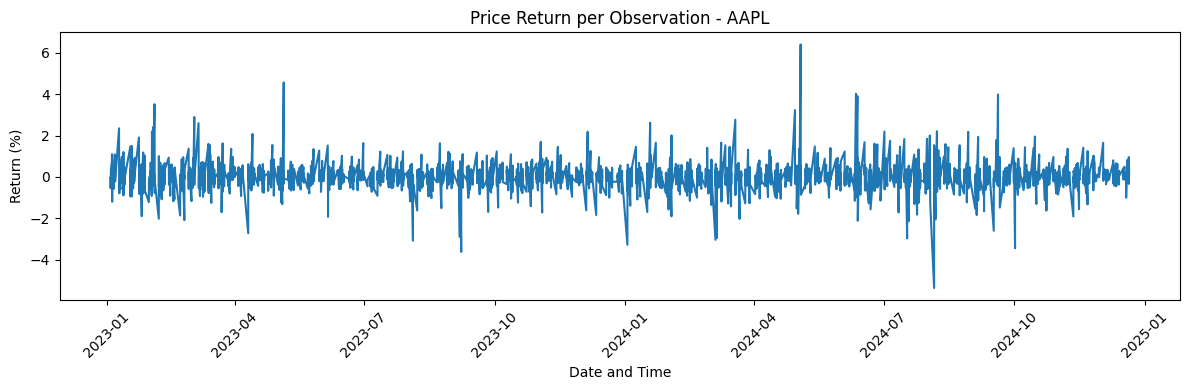

In [7]:
plt.figure(figsize=(12, 4))
plt.plot(stock_df["timestamp"], stock_df["return_pct"])
plt.title("Price Return per Observation - " + str(stock))
plt.xlabel("Date and Time")
plt.ylabel("Return (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Check correlation between numeric columns

        open  high  low  close  volume
open    1.00  1.00  1.0   1.00   -0.19
high    1.00  1.00  1.0   1.00   -0.18
low     1.00  1.00  1.0   1.00   -0.20
close   1.00  1.00  1.0   1.00   -0.19
volume -0.19 -0.18 -0.2  -0.19    1.00


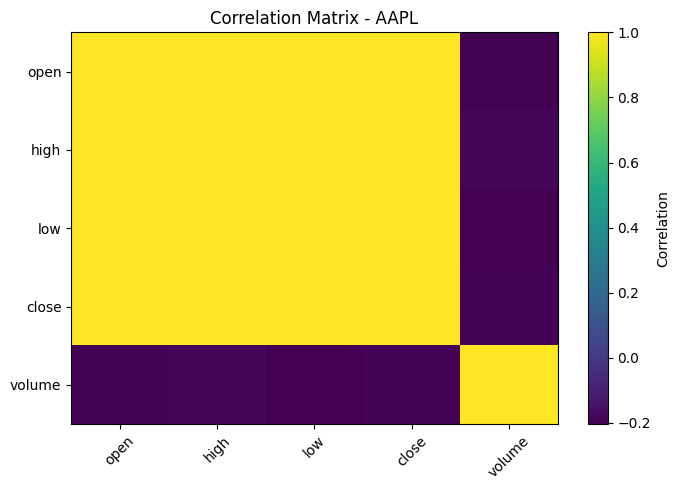

In [8]:
numeric_cols = ["open", "high", "low", "close", "volume"]
corr = stock_df[numeric_cols].corr()

print(corr.round(2))

plt.figure(figsize=(7, 5))
plt.imshow(corr, interpolation="nearest", aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Correlation Matrix - " + str(stock))
plt.tight_layout()
plt.show()

## 8. Simple price prediction using Linear Regression

This is a basic educational example, not reliable financial advice. It uses the previous observation's closing price to predict the next closing price and keeps the time order when splitting the data.

MAE: 0.7739226410153013
RMSE: 1.2812559304063547


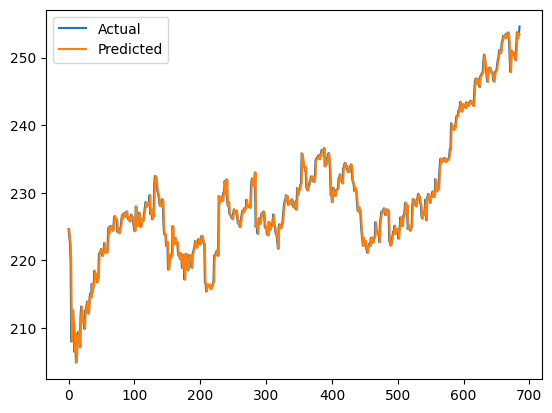

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

stock_df["Previous"] = stock_df["close"].shift(1)
df = stock_df.dropna()

X = df[["Previous"]]
y = df["close"]

split = int(len(df) * 0.8)

model = LinearRegression()
model.fit(X.iloc[:split], y.iloc[:split])

pred = model.predict(X.iloc[split:])
actual = y.iloc[split:]

print("MAE:", mean_absolute_error(actual, pred))
print("RMSE:", np.sqrt(mean_squared_error(actual, pred)))

plt.plot(actual.values, label="Actual")
plt.plot(pred, label="Predicted")
plt.legend()
plt.show()

## 9. Save the analyzed dataset

In [10]:
df.to_csv("analyzed_stock_prices.csv", index=False)
print("Saved file: analyzed_stock_prices.csv")

Saved file: analyzed_stock_prices.csv
